In [1]:
# Imports
import numpy as np
import pandas as pd
import torch
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from google.colab import drive

# Connect to Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Read the Housing.csv
file_path = '/content/drive/My Drive/Datasets/Housing.csv'
df = pd.DataFrame(pd.read_csv(file_path))
print('Number of examples m =', len(df))
df.head()

Number of examples m = 545


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [3]:
# Preprocessing
# Map yes/no variables to 1/0
binary_vars = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
df[binary_vars] = df[binary_vars].apply(lambda x: x.map({'yes': 1, 'no': 0}))

In [4]:
# furnishingstatus has three categories (furnished, semi-furnished, unfurnished)
# One-hot encoding: furnished is the reference category, so two new 0/1 columns are added
df = pd.get_dummies(df, columns=['furnishingstatus'], drop_first=True, dtype=float)

In [5]:
# Input variables: all columns except the price (13 inputs)
variables = [c for c in df.columns if c != 'price']
print(variables)

['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']


In [6]:
# 80/20 split into training and validation set (same split as in Homework 2)
df_train, df_val = train_test_split(df, train_size=0.8, test_size=0.2, random_state=100)


In [7]:
# Standardization of the inputs: the scaler is fitted on the training set only
scaler = StandardScaler()
X_train = scaler.fit_transform(df_train[variables].values.astype(float))
X_val = scaler.transform(df_val[variables].values.astype(float))

In [8]:
# Convert to PyTorch tensors
train_x = torch.tensor(X_train, dtype=torch.float32)
val_x = torch.tensor(X_val, dtype=torch.float32)
train_y = torch.tensor(df_train['price'].values, dtype=torch.float32)
val_y = torch.tensor(df_val['price'].values, dtype=torch.float32)
print('Training examples:', len(train_y), '| Validation examples:', len(val_y))

Training examples: 436 | Validation examples: 109


In [9]:
# Linear model with 14 parameters: params[0] = b, params[1:] = w1 ... w13
def model(x, params):
    return x @ params[1:] + params[0]

def loss_fn(y_p, y):
    squared_diffs = (y_p - y) ** 2
    return squared_diffs.mean()

In [10]:
# Validation accuracy for a regression model: R2 score
def r2_score(y_p, y):
    return 1 - ((y_p - y) ** 2).sum() / ((y - y.mean()) ** 2).sum()

In [11]:
# Training loop from the lecture with training and validation set
def training_loop(n_epochs, optimizer, params, train_x, val_x, train_y, val_y):
    history = {'train_loss': [], 'val_loss': [], 'val_r2': []}
    for epoch in range(1, n_epochs + 1):
        train_p = model(train_x, params)
        train_loss = loss_fn(train_p, train_y)

        # No gradient needed for the validation set
        with torch.no_grad():
            val_p = model(val_x, params)
            val_loss = loss_fn(val_p, val_y)
            val_r2 = r2_score(val_p, val_y)

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        history['train_loss'].append(train_loss.item())
        history['val_loss'].append(val_loss.item())
        history['val_r2'].append(val_r2.item())
        if epoch % 500 == 0:
            print(f'Epoch {epoch}, Training loss {train_loss.item():.4e}, '
                  f'Validation loss {val_loss.item():.4e}, Validation R2 {val_r2.item():.4f}')

    return params, history

In [12]:
# Training with four different learning rates, 5000 epochs each
n_epochs = 5000
learning_rates = [0.1, 0.01, 0.001, 0.0001]
results = {}

for lr in learning_rates:
    print(f'\n--- Learning rate = {lr} ---')
    params = torch.zeros(len(variables) + 1, requires_grad=True)   # all parameters start at zero
    optimizer = optim.SGD([params], lr=lr)
    params, history = training_loop(n_epochs, optimizer, params, train_x, val_x, train_y, val_y)
    results[lr] = {'params': params, 'history': history}


--- Learning rate = 0.1 ---
Epoch 500, Training loss 1.1195e+12, Validation loss 1.1271e+12, Validation R2 0.6807
Epoch 1000, Training loss 1.1195e+12, Validation loss 1.1271e+12, Validation R2 0.6807
Epoch 1500, Training loss 1.1195e+12, Validation loss 1.1271e+12, Validation R2 0.6807
Epoch 2000, Training loss 1.1195e+12, Validation loss 1.1271e+12, Validation R2 0.6807
Epoch 2500, Training loss 1.1195e+12, Validation loss 1.1271e+12, Validation R2 0.6807
Epoch 3000, Training loss 1.1195e+12, Validation loss 1.1271e+12, Validation R2 0.6807
Epoch 3500, Training loss 1.1195e+12, Validation loss 1.1271e+12, Validation R2 0.6807
Epoch 4000, Training loss 1.1195e+12, Validation loss 1.1271e+12, Validation R2 0.6807
Epoch 4500, Training loss 1.1195e+12, Validation loss 1.1271e+12, Validation R2 0.6807
Epoch 5000, Training loss 1.1195e+12, Validation loss 1.1271e+12, Validation R2 0.6807

--- Learning rate = 0.01 ---
Epoch 500, Training loss 1.1195e+12, Validation loss 1.1273e+12, Validat

In [13]:
# Best model = lowest final training loss
best_lr = min(learning_rates, key=lambda lr: results[lr]['history']['train_loss'][-1])
best = results[best_lr]
print(f'\nBest learning rate: {best_lr}')
for name, p in zip(['b (bias)'] + variables, best['params'].data):
    print(f'{name:>32s} = {p.item():.2f}')


Best learning rate: 0.1
                        b (bias) = 4795728.50
                            area = 523109.88
                        bedrooms = 66116.68
                       bathrooms = 571341.56
                         stories = 357741.38
                        mainroad = 198127.59
                       guestroom = 145258.94
                        basement = 132749.52
                 hotwaterheating = 193370.20
                 airconditioning = 387432.28
                         parking = 208377.27
                        prefarea = 255018.14
 furnishingstatus_semi-furnished = -50208.83
    furnishingstatus_unfurnished = -200559.44


In [14]:
# Cost J = MSE / 2 like in Homework 2, for the comparison
print(f"Training cost J = {best['history']['train_loss'][-1] / 2:.4e}")
print(f"Validation cost J = {best['history']['val_loss'][-1] / 2:.4e}")
print(f"Validation R2 = {best['history']['val_r2'][-1]:.4f}")

Training cost J = 5.5974e+11
Validation cost J = 5.6356e+11
Validation R2 = 0.6807


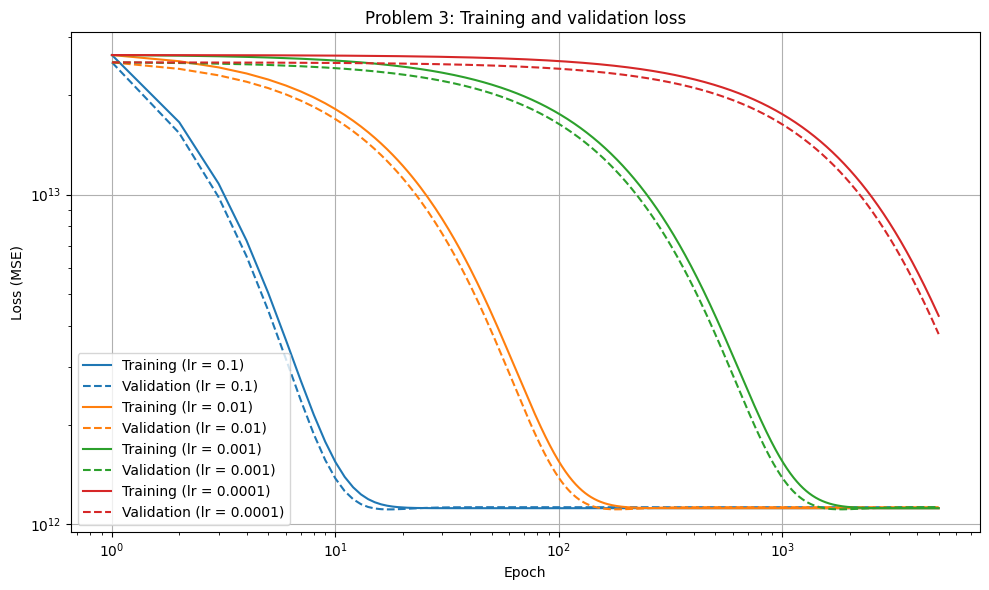

In [15]:
# Plot training (solid) and validation loss (dashed) for every learning rate
epochs = range(1, n_epochs + 1)
plt.figure(figsize=(10, 6))
for lr, color in zip(learning_rates, ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']):
    plt.plot(epochs, results[lr]['history']['train_loss'], color=color, label=f'Training (lr = {lr})')
    plt.plot(epochs, results[lr]['history']['val_loss'], color=color, linestyle='--', label=f'Validation (lr = {lr})')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Problem 3: Training and validation loss')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig('problem_3_loss.png', dpi=110)
plt.show()

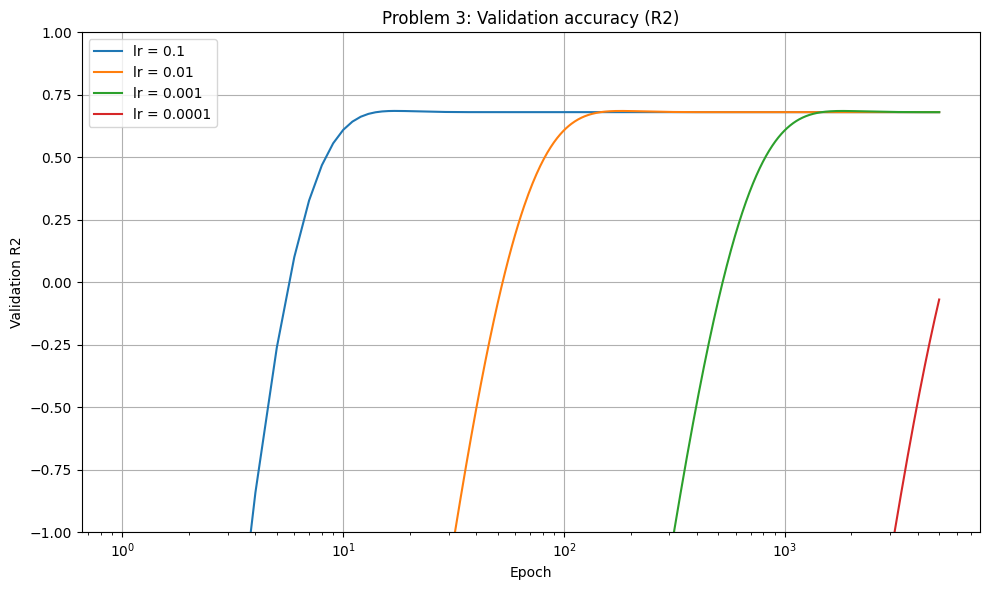

In [16]:
# Plot the validation R2 for every learning rate
plt.figure(figsize=(10, 6))
for lr in learning_rates:
    plt.plot(epochs, results[lr]['history']['val_r2'], label=f'lr = {lr}')
plt.xscale('log')
plt.ylim(-1, 1)
plt.xlabel('Epoch')
plt.ylabel('Validation R2')
plt.title('Problem 3: Validation accuracy (R2)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig('problem_3_r2.png', dpi=110)
plt.show()